# Análise dos horários dos sensores — 2024

Este notebook verifica os arquivos do dataset de 2024 e calcula os intervalos entre medições de temperatura e umidade do ar e do solo. Os timestamps são convertidos de Unix em milissegundos para o fuso `America/Bahia`.

## 1. Configuração

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

PROJECT_DIR = Path("/home/gabrielvaz/Músicas/PI4-ICA-IoT-main")
NOTEBOOK_DIR = PROJECT_DIR / "codes"
DATASET_DIR = (
    NOTEBOOK_DIR
    / "IoT Dataset from an Evolving Tomato Cultivation Te"
    / "2024"
)
OUTPUT_DIR = PROJECT_DIR / "outputs" / "eda01"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

if not DATASET_DIR.exists():
    raise FileNotFoundError(f"Pasta do dataset não encontrada: {DATASET_DIR}")

print(f"Dataset: {DATASET_DIR}")
print(f"Resultados: {OUTPUT_DIR}")

Dataset: /home/gabrielvaz/Músicas/PI4-ICA-IoT-main/codes/IoT Dataset from an Evolving Tomato Cultivation Te/2024
Resultados: /home/gabrielvaz/Músicas/PI4-ICA-IoT-main/outputs/eda01


## 2. Arquivos disponíveis

In [2]:
csv_files = sorted(DATASET_DIR.glob("*.csv"))

print(f"Total de CSVs encontrados: {len(csv_files)}")
for indice, csv_file in enumerate(csv_files, start=1):
    print(f"[{indice}] {csv_file.name}")

if not csv_files:
    raise FileNotFoundError(f"Nenhum CSV encontrado em: {DATASET_DIR}")

Total de CSVs encontrados: 7
[1] environmental2024.csv
[2] indicators2024.csv
[3] pressure2024.csv
[4] soil2024.csv
[5] valve_controller2024.csv
[6] water_meter2024.csv
[7] water_potential2024.csv


In [3]:
resumo_arquivos = []

for csv_file in csv_files:
    amostra = pd.read_csv(csv_file, nrows=5)
    colunas_validas = [
        coluna for coluna in amostra.columns
        if not str(coluna).startswith("Unnamed")
    ]
    resumo_arquivos.append({
        "arquivo": csv_file.name,
        "tamanho_MB": round(csv_file.stat().st_size / (1024 ** 2), 2),
        "colunas": ", ".join(colunas_validas),
    })

resumo_arquivos_df = pd.DataFrame(resumo_arquivos)
display(resumo_arquivos_df)
resumo_arquivos_df.to_csv(OUTPUT_DIR / "resumo_arquivos_2024.csv", index=False)

,arquivo,tamanho_MB,colunas
0,environmental2024.csv,0.94,"ts_generation, generated_by, co2, pressure, te..."
1,indicators2024.csv,0.01,"ts_generation, gdd, standard_day_degree_daily,..."
2,pressure2024.csv,13.63,"ts_generation, generated_by, line, pressure"
3,soil2024.csv,18.05,"ts_generation, generated_by, line, electrical_..."
4,valve_controller2024.csv,5.55,"ts_generation, generated_by, line, valve_state"
5,water_meter2024.csv,5.75,"ts_generation, device_identifier, line, curren..."
6,water_potential2024.csv,12.41,"ts_generation, generated_by, line, water_poten..."


## 3. Carregamento dos sensores

- `environmental2024.csv`: temperatura e umidade do ar.
- `soil2024.csv`: temperatura e umidade do solo.

In [4]:
def carregar_csv(nome_arquivo):
    caminho = DATASET_DIR / nome_arquivo
    if not caminho.exists():
        raise FileNotFoundError(f"Arquivo não encontrado: {caminho}")

    dados = pd.read_csv(caminho)
    dados = dados.loc[:, ~dados.columns.astype(str).str.startswith("Unnamed")]
    return dados


df_ambiente = carregar_csv("environmental2024.csv")
df_solo = carregar_csv("soil2024.csv")

print(f"Registros ambientais: {len(df_ambiente):,}")
print(f"Registros do solo: {len(df_solo):,}")
display(df_ambiente.head(3))
display(df_solo.head(3))

Registros ambientais: 9,327
Registros do solo: 182,153


,ts_generation,generated_by,co2,pressure,temperature,humidity
0,1718150672436,abc0d16aaf15b3a4ee2e561195dfd82ab260497412e326...,489.0,NaN,17.6,81.0
1,1718151284591,abc0d16aaf15b3a4ee2e561195dfd82ab260497412e326...,489.0,NaN,17.5,86.0
2,1718151896739,abc0d16aaf15b3a4ee2e561195dfd82ab260497412e326...,510.0,NaN,17.3,90.0


,ts_generation,generated_by,line,electrical_conductivity,humidity,temperature
0,1688047456101,9d5fe860849cee394ff52cd69a6d69642ea9f4756dac17...,2,723.0,31.90,29.1
1,1688048057491,9d5fe860849cee394ff52cd69a6d69642ea9f4756dac17...,2,723.0,31.90,29.0
2,1688048658856,9d5fe860849cee394ff52cd69a6d69642ea9f4756dac17...,2,723.0,31.74,29.0


## 4. Preparação dos timestamps

In [5]:
def preparar_timestamps(dados):
    resultado = dados.copy()
    resultado["timestamp"] = (
        pd.to_datetime(resultado["ts_generation"], unit="ms", utc=True, errors="coerce")
        .dt.tz_convert("America/Bahia")
    )
    resultado = resultado.dropna(subset=["timestamp"])
    return resultado.sort_values("timestamp").reset_index(drop=True)


df_ambiente = preparar_timestamps(df_ambiente)
df_solo = preparar_timestamps(df_solo)

print("Período ambiental:", df_ambiente["timestamp"].min(), "até", df_ambiente["timestamp"].max())
print("Período do solo:", df_solo["timestamp"].min(), "até", df_solo["timestamp"].max())

Período ambiental: 2024-06-11 21:04:32.436000-03:00 até 2024-09-04 23:33:20.814000-03:00
Período do solo: 2023-06-06 11:57:15.025000-03:00 até 2024-09-23 10:27:31.453000-03:00


## 5. Intervalos entre as medições

Os intervalos são calculados separadamente por dispositivo (`generated_by`). Isso evita misturar timestamps de sensores diferentes e produzir intervalos artificiais.

In [6]:
def criar_serie_sensor(dados, coluna, nome_sensor, fonte):
    colunas = ["timestamp", "generated_by", coluna]
    if "line" in dados.columns:
        colunas.append("line")

    serie = dados[colunas].dropna(subset=[coluna]).copy()
    serie = serie.rename(columns={coluna: "valor"})
    serie["sensor"] = nome_sensor
    serie["fonte"] = fonte
    return serie


leituras = pd.concat([
    criar_serie_sensor(df_ambiente, "temperature", "Temperatura do ar", "environmental2024.csv"),
    criar_serie_sensor(df_ambiente, "humidity", "Umidade do ar", "environmental2024.csv"),
    criar_serie_sensor(df_solo, "temperature", "Temperatura do solo", "soil2024.csv"),
    criar_serie_sensor(df_solo, "humidity", "Umidade do solo", "soil2024.csv"),
], ignore_index=True)

colunas_grupo = ["sensor", "generated_by"]
if "line" in leituras.columns:
    colunas_grupo.append("line")

leituras = leituras.sort_values(colunas_grupo + ["timestamp"])
leituras["intervalo"] = leituras.groupby(colunas_grupo, dropna=False)["timestamp"].diff()
leituras["intervalo_minutos"] = leituras["intervalo"].dt.total_seconds() / 60

display(leituras.head())

,timestamp,generated_by,valor,sensor,fonte,line,intervalo,intervalo_minutos
0,2024-06-11 21:04:32.436000-03:00,abc0d16aaf15b3a4ee2e561195dfd82ab260497412e326...,17.6,Temperatura do ar,environmental2024.csv,NaN,NaT,NaN
1,2024-06-11 21:14:44.591000-03:00,abc0d16aaf15b3a4ee2e561195dfd82ab260497412e326...,17.5,Temperatura do ar,environmental2024.csv,NaN,0 days 00:10:12.155000,10.202583
2,2024-06-11 21:24:56.739000-03:00,abc0d16aaf15b3a4ee2e561195dfd82ab260497412e326...,17.3,Temperatura do ar,environmental2024.csv,NaN,0 days 00:10:12.148000,10.202467
3,2024-06-11 21:35:08.872000-03:00,abc0d16aaf15b3a4ee2e561195dfd82ab260497412e326...,17.2,Temperatura do ar,environmental2024.csv,NaN,0 days 00:10:12.133000,10.202217
4,2024-06-11 21:45:20.995000-03:00,abc0d16aaf15b3a4ee2e561195dfd82ab260497412e326...,17.1,Temperatura do ar,environmental2024.csv,NaN,0 days 00:10:12.123000,10.202050


In [23]:
def moda_ou_na(serie):
    moda = serie.dropna().mode()
    return moda.iloc[0] if not moda.empty else pd.NA


resumo_intervalos = (
    leituras.groupby(["sensor", "fonte"], as_index=False)
    .agg(
        quantidade_leituras=("valor", "size"),
        primeiro_horario=("timestamp", "min"),
        ultimo_horario=("timestamp", "max"),
        intervalo_mediano_min=("intervalo_minutos", "median"),
        intervalo_medio_min=("intervalo_minutos", "mean"),
        intervalo_mais_comum_min=("intervalo_minutos", moda_ou_na),
        intervalo_minimo_min=("intervalo_minutos", "min"),
        intervalo_maximo_min=("intervalo_minutos", "max"),
    )
)

colunas_numericas = [
    "intervalo_mediano_min",
    "intervalo_medio_min",
    "intervalo_mais_comum_min",
    "intervalo_minimo_min",
    "intervalo_maximo_min",
]
resumo_intervalos[colunas_numericas] = resumo_intervalos[colunas_numericas].round(2)

display(resumo_intervalos)
resumo_intervalos.to_csv(OUTPUT_DIR / "resumo_intervalos_sensores_2024.csv", index=False)

,sensor,fonte,quantidade_leituras,primeiro_horario,ultimo_horario,intervalo_mediano_min,intervalo_medio_min,intervalo_mais_comum_min,intervalo_minimo_min,intervalo_maximo_min
0,Temperatura do ar,environmental2024.csv,9327,2024-06-11 21:04:32.436000-03:00,2024-09-04 23:33:20.814000-03:00,10.00,13.14,10.00,9.34,24921.96
1,Temperatura do solo,soil2024.csv,182134,2023-06-06 11:57:15.025000-03:00,2024-09-23 10:27:31.453000-03:00,10.02,16.66,10.02,2.82,380502.70
2,Umidade do ar,environmental2024.csv,9325,2024-06-11 21:04:32.436000-03:00,2024-09-04 23:33:20.814000-03:00,10.00,13.14,10.00,9.34,24921.96
3,Umidade do solo,soil2024.csv,181857,2023-06-06 11:57:15.025000-03:00,2024-09-23 10:27:31.453000-03:00,10.02,16.67,10.02,2.82,380743.25


## 6. Construção da série temporal tratada

Para comparar os quatro sensores, as leituras são agregadas pela mediana em intervalos regulares de 10 minutos. Valores fora de limites físicos amplos são tratados como ausentes. Apenas lacunas internas de até três intervalos (30 minutos) são interpoladas; lacunas maiores continuam visíveis.

In [24]:
inicio_2024 = pd.Timestamp("2024-01-01", tz="America/Bahia")
fim_2024 = pd.Timestamp("2025-01-01", tz="America/Bahia")

ambiente_2024 = df_ambiente[
    df_ambiente["timestamp"].between(inicio_2024, fim_2024, inclusive="left")
].copy()

solo_2024 = df_solo[
    df_solo["timestamp"].between(inicio_2024, fim_2024, inclusive="left")
].copy()

serie_ar = (
    ambiente_2024
    .set_index("timestamp")[["temperature", "humidity"]]
    .rename(columns={
        "temperature": "Temperatura do ar",
        "humidity": "Umidade do ar",
    })
    .resample("10min")
    .median()
)

serie_solo = (
    solo_2024
    .set_index("timestamp")[["temperature", "humidity"]]
    .rename(columns={
        "temperature": "Temperatura do solo",
        "humidity": "Umidade do solo",
    })
    .resample("10min")
    .median()
)

serie_original = serie_ar.join(serie_solo, how="outer").sort_index()

limites = {
    "Temperatura do ar": (-10, 60),
    "Umidade do ar": (0, 100),
    "Temperatura do solo": (-10, 60),
    "Umidade do solo": (0, 100),
}

for coluna, (limite_inferior, limite_superior) in limites.items():
    serie_original.loc[
        ~serie_original[coluna].between(limite_inferior, limite_superior),
        coluna,
    ] = pd.NA

serie_tratada = serie_original.interpolate(
    method="time",
    limit=3,
    limit_area="inside",
)

resumo_tratamento = pd.DataFrame({
    "registros_observados": serie_original.notna().sum(),
    "lacunas_antes": serie_original.isna().sum(),
    "lacunas_depois": serie_tratada.isna().sum(),
})
resumo_tratamento["valores_interpolados"] = (
    resumo_tratamento["lacunas_antes"] - resumo_tratamento["lacunas_depois"]
)

display(resumo_tratamento)

serie_tratada.to_csv(
    OUTPUT_DIR / "serie_temporal_tratada_2024.csv",
    index_label="timestamp",
)

,registros_observados,lacunas_antes,lacunas_depois,valores_interpolados
Temperatura do ar,9327,5797,5635,162
Umidade do ar,9325,5799,5635,164
Temperatura do solo,13661,1463,1441,22
Umidade do solo,13636,1488,1466,22


## 7. Cobertura dos timestamps

Cada ponto representa um intervalo de 10 minutos que contém uma leitura observada. Espaços em branco mostram períodos sem dados; valores interpolados não entram neste gráfico.

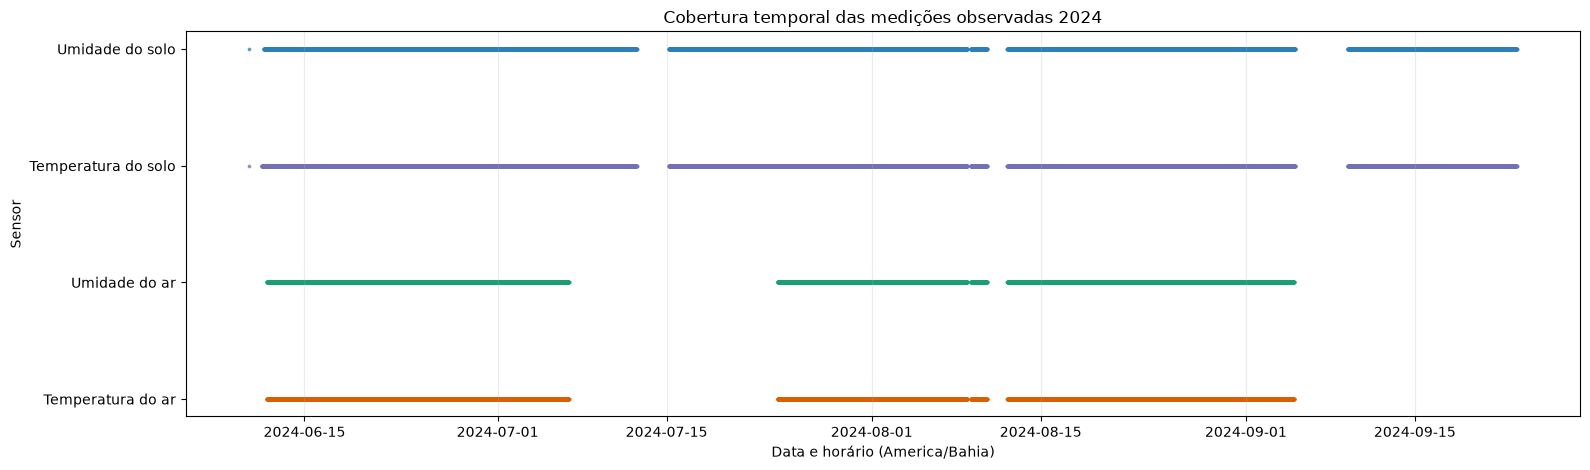

In [32]:
cores = {
    "Temperatura do ar": "#d95f02",
    "Umidade do ar": "#1b9e77",
    "Temperatura do solo": "#7570b3",
    "Umidade do solo": "#2c7fb8",
}

fig, ax = plt.subplots(figsize=(16, 4.8))

for posicao, coluna in enumerate(serie_original.columns):
    timestamps_validos = serie_original.index[serie_original[coluna].notna()]
    ax.scatter(
        timestamps_validos,
        [posicao] * len(timestamps_validos),
        s=3,
        alpha=0.65,
        color=cores[coluna],
        label=coluna,
    )

ax.set_yticks(range(len(serie_original.columns)))
ax.set_yticklabels(serie_original.columns)
ax.set_title("Cobertura temporal das medições observadas 2024")
ax.set_xlabel("Data e horário (America/Bahia)")
ax.set_ylabel("Sensor")
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

## 8. Série temporal tratada completa

A linha é interrompida quando a lacuna supera 30 minutos. Isso evita criar artificialmente dados durante períodos longos sem transmissão.

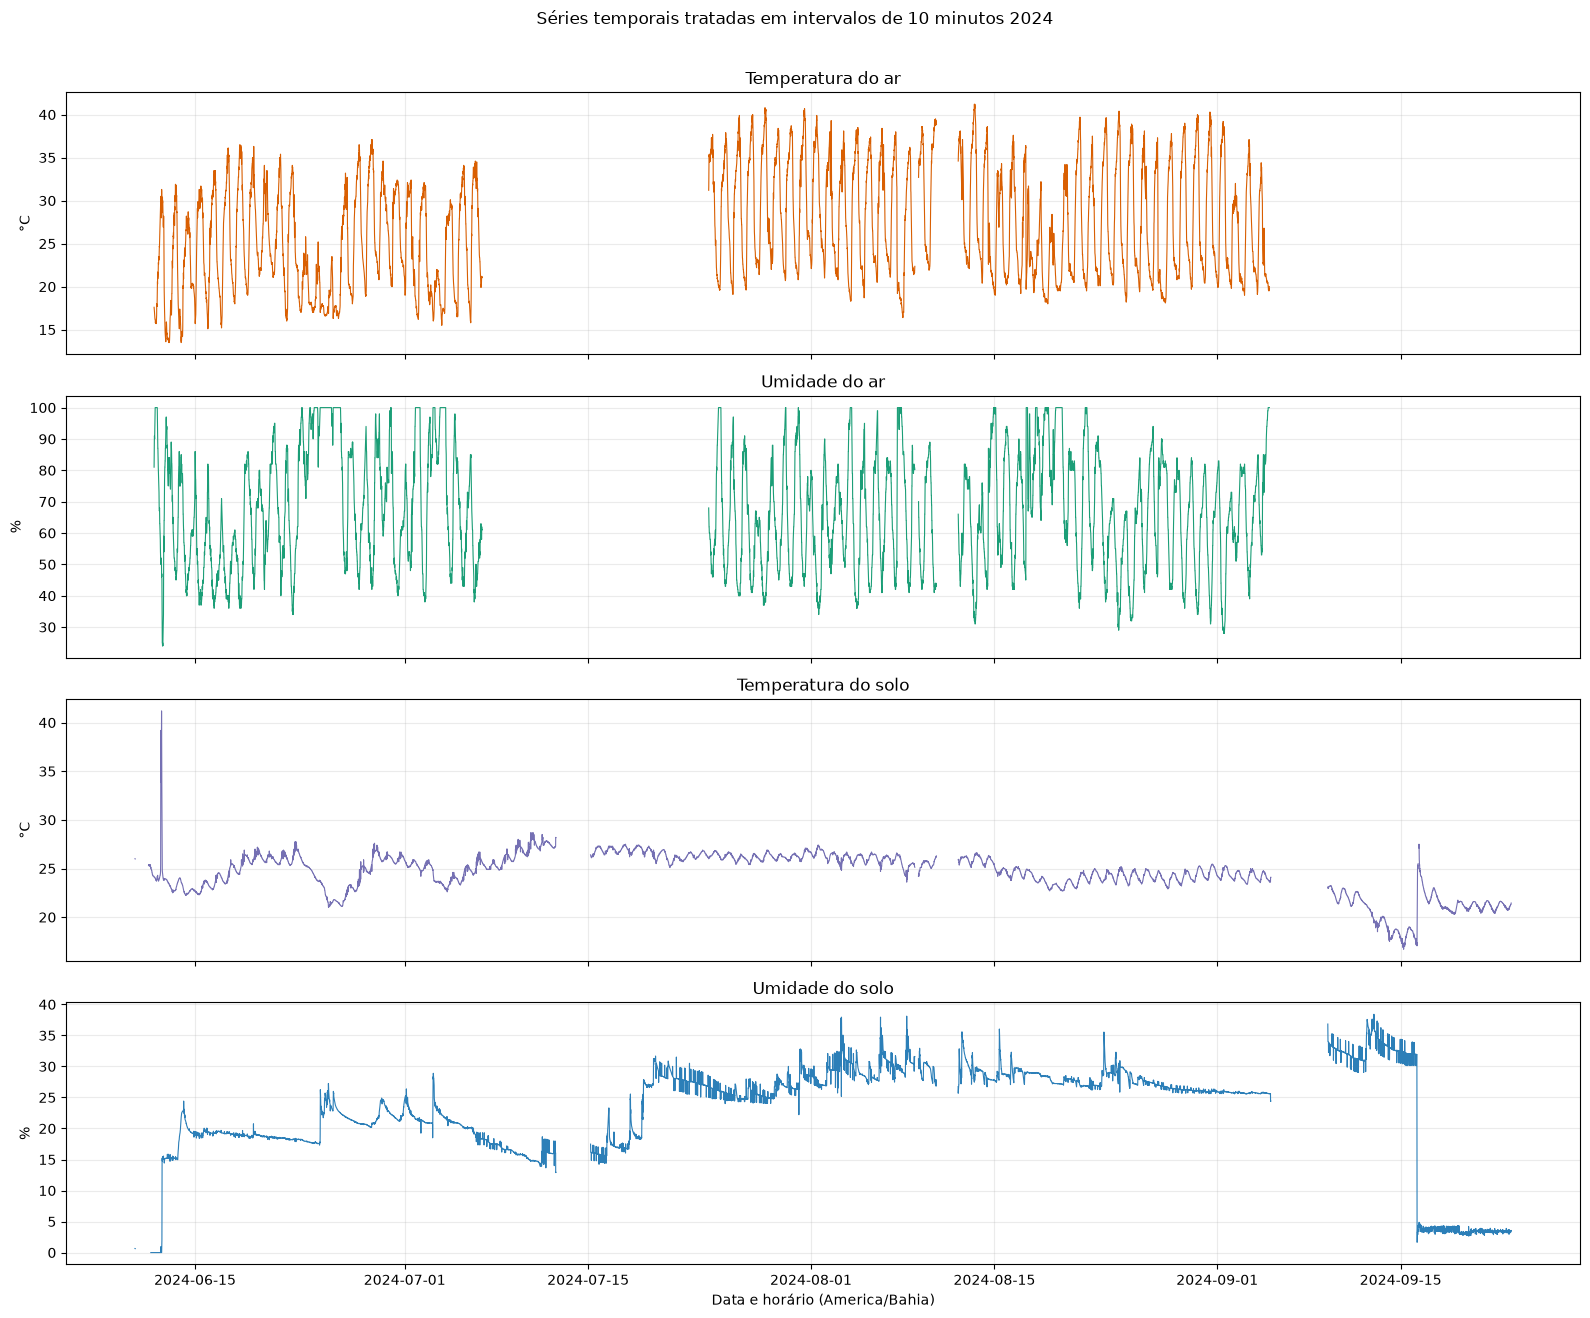

In [33]:
unidades = {
    "Temperatura do ar": "°C",
    "Umidade do ar": "%",
    "Temperatura do solo": "°C",
    "Umidade do solo": "%",
}

fig, eixos = plt.subplots(4, 1, figsize=(16, 13), sharex=True)

for eixo, coluna in zip(eixos, serie_tratada.columns):
    eixo.plot(
        serie_tratada.index,
        serie_tratada[coluna],
        color=cores[coluna],
        linewidth=0.8,
    )
    eixo.set_title(coluna)
    eixo.set_ylabel(unidades[coluna])
    eixo.grid(alpha=0.25)

eixos[-1].set_xlabel("Data e horário (America/Bahia)")
fig.suptitle("Séries temporais tratadas em intervalos de 10 minutos 2024", y=1.01)
plt.tight_layout()
plt.show()

## 9. Recorte detalhado

Altere `data_inicial` e `data_final` para investigar outro período. Os pontos destacados representam valores preenchidos pela interpolação curta.

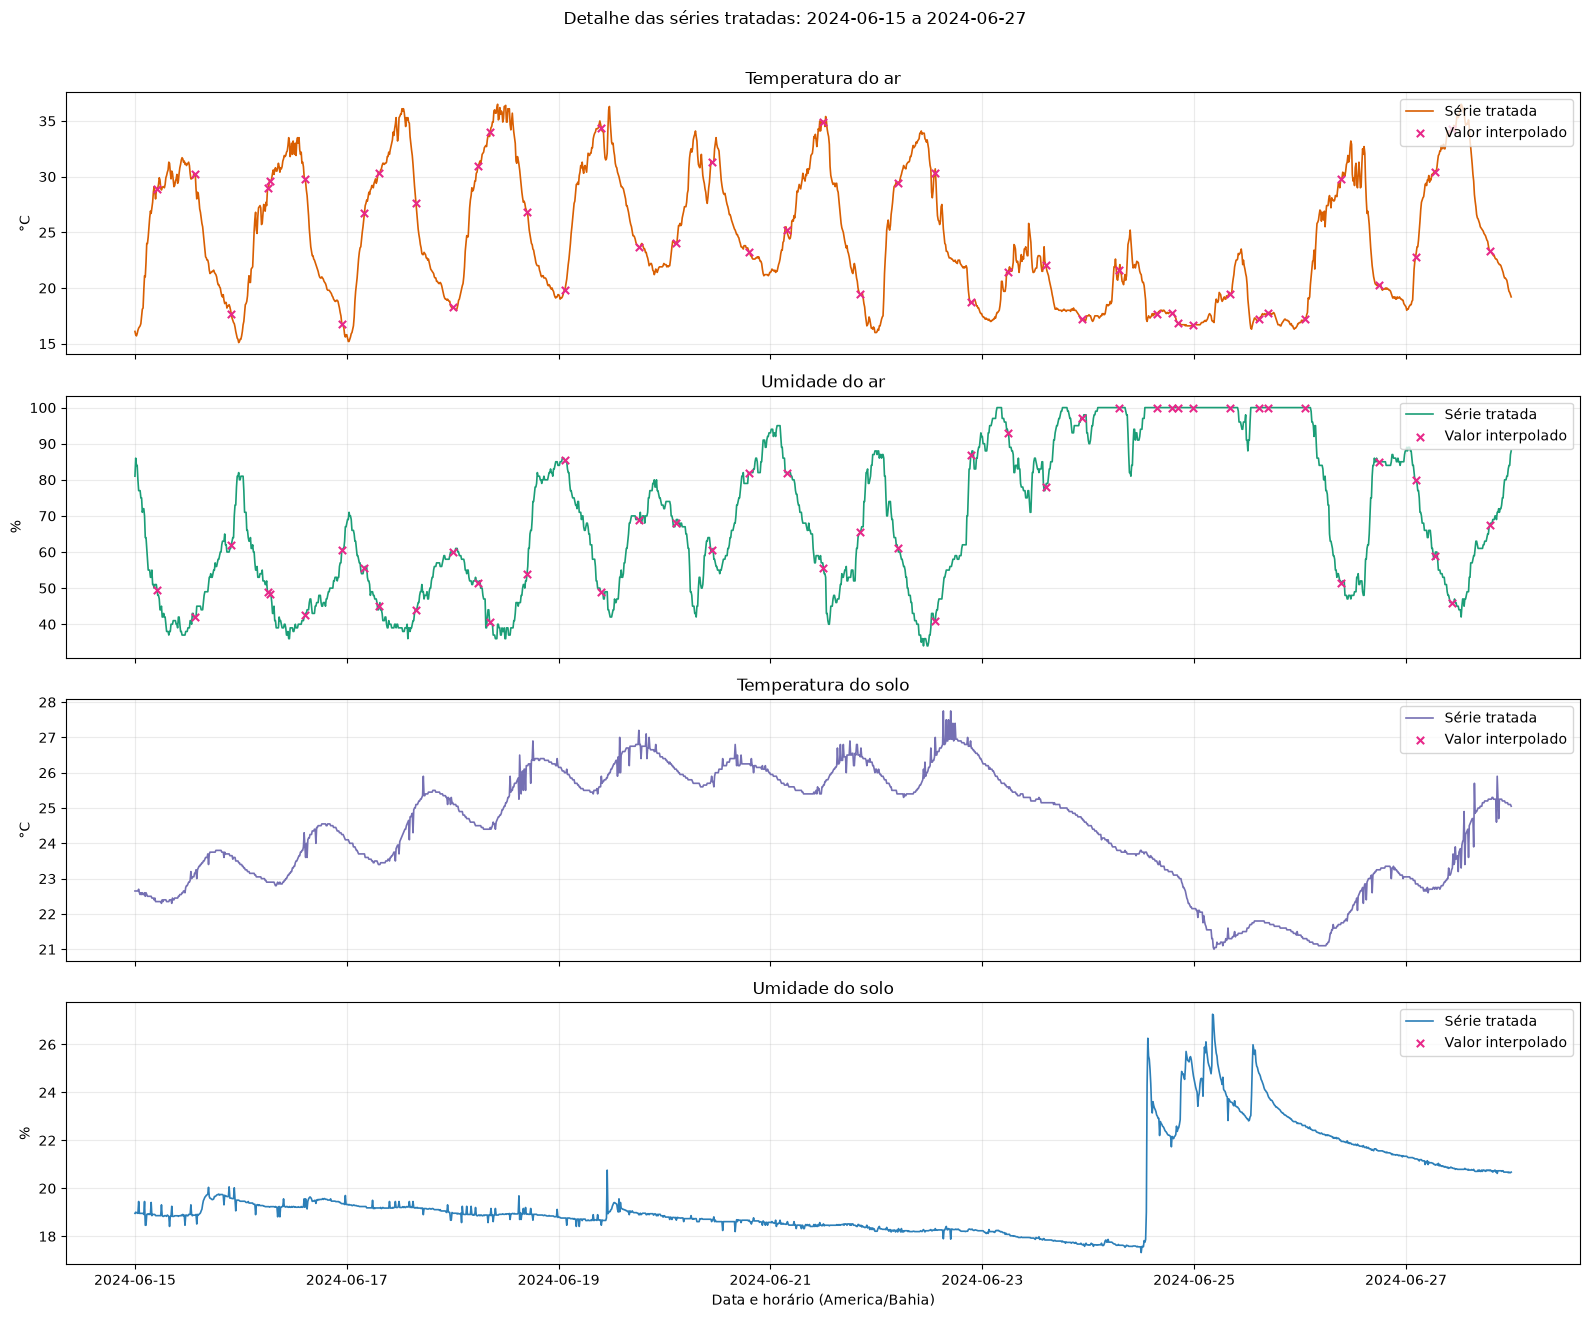

In [34]:
data_inicial = "2024-06-15"
data_final = "2024-06-27"

recorte_original = serie_original.loc[data_inicial:data_final]
recorte_tratado = serie_tratada.loc[data_inicial:data_final]
valores_interpolados = recorte_original.isna() & recorte_tratado.notna()

fig, eixos = plt.subplots(4, 1, figsize=(16, 13), sharex=True)

for eixo, coluna in zip(eixos, recorte_tratado.columns):
    eixo.plot(
        recorte_tratado.index,
        recorte_tratado[coluna],
        color=cores[coluna],
        linewidth=1.2,
        label="Série tratada",
    )
    eixo.scatter(
        recorte_tratado.index[valores_interpolados[coluna]],
        recorte_tratado.loc[valores_interpolados[coluna], coluna],
        color="#e7298a",
        marker="x",
        s=28,
        label="Valor interpolado",
        zorder=3,
    )
    eixo.set_title(coluna)
    eixo.set_ylabel(unidades[coluna])
    eixo.grid(alpha=0.25)
    eixo.legend(loc="upper right")

eixos[-1].set_xlabel("Data e horário (America/Bahia)")
fig.suptitle(f"Detalhe das séries tratadas: {data_inicial} a {data_final}", y=1.01)
plt.tight_layout()
plt.show()

## Como interpretar

- A cobertura mostra em quais datas cada tipo de sensor realmente transmitiu dados.
- A série completa preserva lacunas longas, que aparecem como interrupções nas linhas.
- No recorte detalhado, marcadores cor-de-rosa identificam somente os valores interpolados em lacunas de até 30 minutos.
- A série é uma visão agregada: quando vários dispositivos transmitem no mesmo intervalo, é utilizada a mediana.